<!-- ## VaR y CVaR -->

Nicole Getzabel Flores Godines



**Datos y parámetros**

Descargamos los precios de Apple, Microsoft y NVIDIA del último año. Calculamos los rendimientos, la volatilidad y la correlación.


In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [3]:
tickers = ['AAPL', 'MSFT', 'NVDA']
V0 = 100000
M = 10000
T = 1

datos = yf.download(tickers, period='1y')['Close']
datos = datos[tickers]
datos = datos.dropna()

rend = np.log(datos / datos.shift(1)).dropna()

mu = rend.mean().values * 252
sigma = rend.std().values * np.sqrt(252)

print(pd.DataFrame({'mu': mu, 'sigma': sigma}, index=tickers))

R = rend.corr()
print(R.round(4))

[*********************100%***********************]  3 of 3 completed

            mu     sigma
AAPL  0.267540  0.250392
MSFT  0.027770  0.336959
NVDA -0.107787  0.386673
Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.1555  0.0600
MSFT    0.1555  1.0000  0.2334
NVDA    0.0600  0.2334  1.0000


**Método de Cholesky**

Usamos Cholesky para generar simulaciones donde los movimientos de las tres acciones están relacionados.


In [4]:
Sigma = rend.cov().values *252
L = np.linalg.cholesky(Sigma)

np.random.seed(0)
epsilon = np.random.normal(0, 1, [3, M])

Z = L @ epsilon
ZT = Z.T

pd.DataFrame(ZT[:5], columns=tickers).round(4)

,AAPL,MSFT,NVDA
0,0.4417,0.0251,0.1472
1,0.1002,-0.2564,-0.0640
2,0.2451,0.6283,0.4823
3,0.5611,0.1809,0.2297
4,0.4676,0.0387,-0.9134


**Precios simulados**

Calculamos los posibles precios de las acciones dentro de un año.


In [5]:
S0 = datos.iloc[-1].values
var = np.diag(Sigma)

ST = S0 * np.exp((mu - var / 2) * T + np.sqrt(T) * ZT)

pd.DataFrame({
    'Precio inicial': S0,
    'Precio promedio': ST.mean(axis=0)
}, index=tickers).round(2)

,Precio inicial,Precio promedio
AAPL,355.63,462.25
MSFT,521.13,536.84
NVDA,173.73,155.66


**Escenarios del portafolio**

Comparamos tres escenarios: todo en Apple, inversión casi igual y mayor inversión en NVIDIA. Calculamos las ganancias, pérdidas y sus probabilidades.


In [6]:
escenarios = {
    'A': [1, 0, 0],
    'B': [0.33, 0.33, 0.34],
    'C': [0.2, 0.2, 0.6]
}

ganancias_todas = {}
resultados = []

for nombre, pesos in escenarios.items():
    VF = np.sum((ST / S0) * pesos, axis=1) * V0
    ganancia = VF - V0
    ganancias_todas[nombre] = ganancia

    positivas = ganancia[ganancia > 0]
    negativas = ganancia[ganancia < 0]

    resultados.append({
        'Escenario': nombre,
        'Prob. ganar': np.mean(ganancia > 0),
        'Prob. perder': np.mean(ganancia < 0),
        'Promedio ganancia': ganancia.mean(),
        'Cuando gano': positivas.mean(),
        'Cuando pierdo': negativas.mean(),
        'Máximo': ganancia.max(),
        'Mínimo': ganancia.min(),
        'Percentil 5%': np.percentile(ganancia, 5)
    })

pd.DataFrame(resultados).round(2)


,Escenario,Prob. ganar,Prob. perder,Promedio ganancia,Cuando gano,Cuando pierdo,Máximo,Mínimo,Percentil 5%
0,A,0.83,0.17,29980.16,38843.18,-11860.62,228083.63,-50356.34,-15848.91
1,B,0.59,0.41,7351.52,21457.22,-13345.89,136782.50,-51271.88,-24991.36
2,C,0.44,0.56,357.61,22527.11,-17374.81,170439.15,-61171.20,-33981.91


**Gráficas**

Mostramos las ganancias y pérdidas de cada escenario en histogramas.


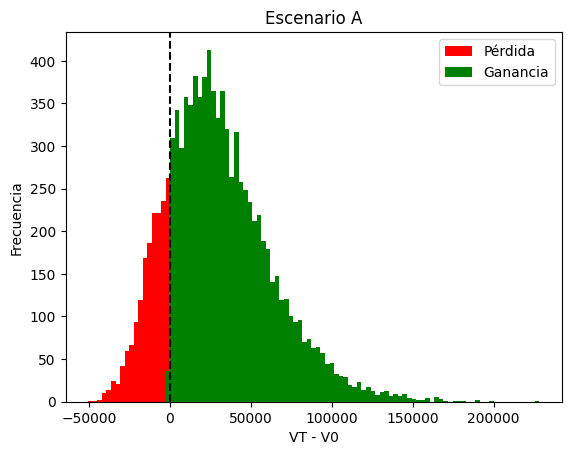

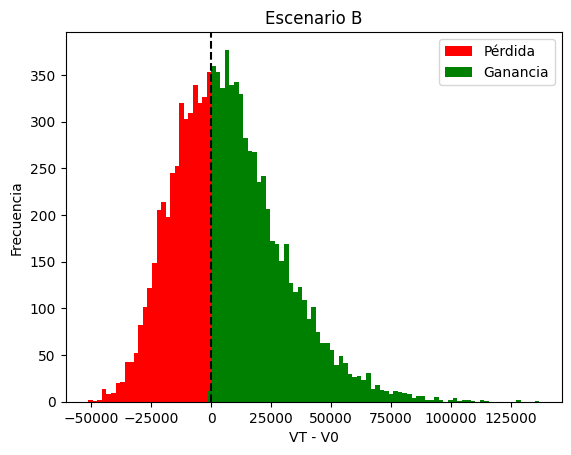

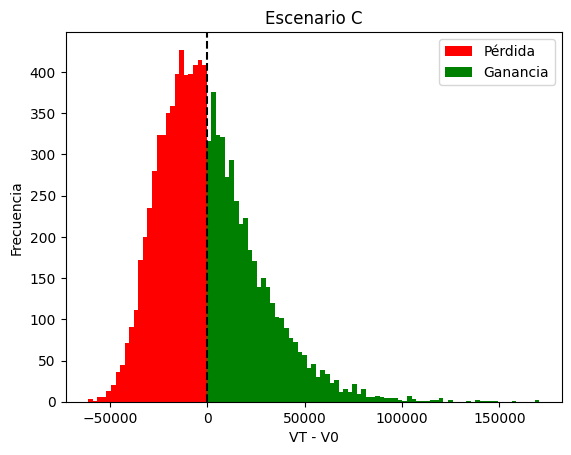

In [7]:
for nombre, ganancia in ganancias_todas.items():
    bins = np.linspace(ganancia.min(), ganancia.max(), 100)

    plt.hist(ganancia[ganancia < 0], bins=bins, color='red', label='Pérdida')
    plt.hist(ganancia[ganancia >= 0], bins=bins, color='green', label='Ganancia')
    plt.axvline(0, color='black', linestyle='--')
    plt.xlabel('VT - V0')
    plt.ylabel('Frecuencia')
    plt.title('Escenario ' + nombre)
    plt.legend()
    plt.show()

In [8]:
resumen = {}

for nombre, ganancia in ganancias_todas.items():
    VT = ganancia + V0
    resumen[nombre] = {
        'VT promedio': VT.mean(),
        'VT en miles': VT.mean() / 1000,
        'Ganancia promedio': ganancia.mean(),
        'Prob. perder': np.mean(ganancia < 0)
    }

tabla = pd.DataFrame(resumen).T
tabla.round(2)

,VT promedio,VT en miles,Ganancia promedio,Prob. perder
A,129980.16,129.98,29980.16,0.17
B,107351.52,107.35,7351.52,0.41
C,100357.61,100.36,357.61,0.56


**VaR y CVaR**

Calculamos el VaR y CVaR de los tres escenarios con un nivel de confianza del 95% para conocer las posibles pérdidas de cada portafolio.

In [9]:
resultados_riesgo = []

for nombre, ganancia in ganancias_todas.items():
    VaR = -np.percentile(ganancia, 5)
    CVaR = -ganancia[ganancia <= -VaR].mean()

    resultados_riesgo.append({
        'Escenario': nombre,
        'VaR 95%': VaR,
        'CVaR 95%': CVaR
    })

pd.DataFrame(resultados_riesgo).round(2)


,Escenario,VaR 95%,CVaR 95%
0,A,15848.91,23575.16
1,B,24991.36,30974.98
2,C,33981.91,40010.42


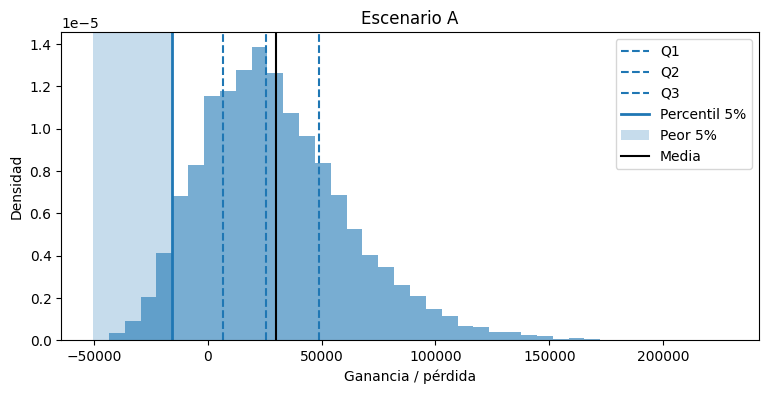

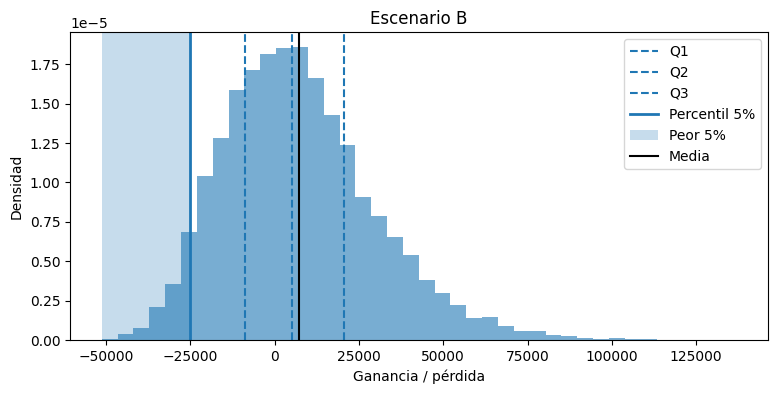

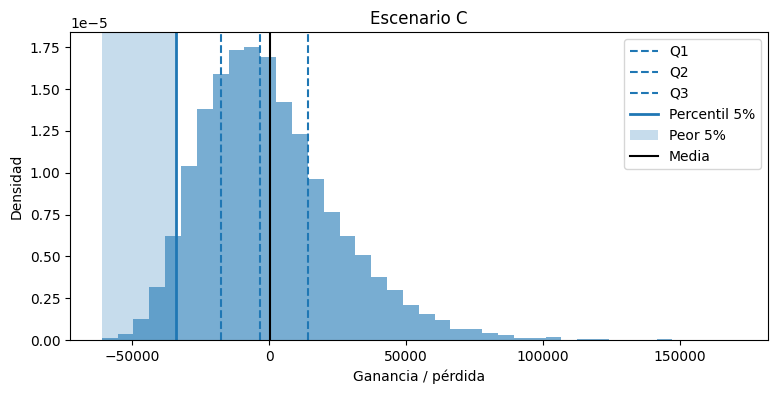

In [12]:
for nombre, ganancia in ganancias_todas.items():

    q1, q2, q3 = np.percentile(ganancia, [25, 50, 75])
    p5 = np.percentile(ganancia, 5)

    plt.figure(figsize=(9, 4))
    plt.hist(ganancia, bins=40, density=True, alpha=0.6)

    plt.axvline(q1, linestyle='--', label='Q1')
    plt.axvline(q2, linestyle='--', label='Q2')
    plt.axvline(q3, linestyle='--', label='Q3')
    plt.axvline(p5, linewidth=2, label='Percentil 5%')

    plt.axvspan(ganancia.min(), p5, alpha=0.25, label='Peor 5%')

    plt.axvline(ganancia.mean(), color='black', label='Media')

    plt.title('Escenario ' + nombre)
    plt.xlabel('Ganancia / pérdida')
    plt.ylabel('Densidad')
    plt.legend()
    plt.show()


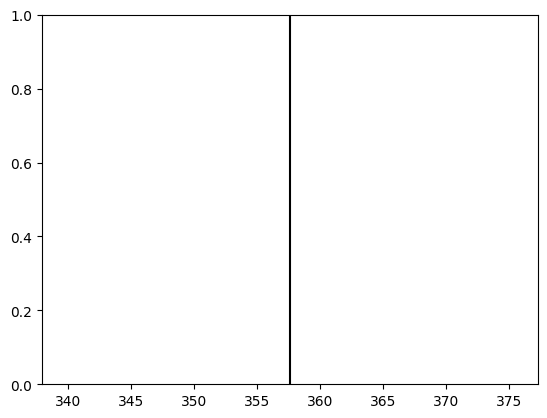

**Conclusión**

En esta actividad aprendí a utilizar la simulación de Monte Carlo para analizar el comportamiento de diferentes portafolios de inversión. A través de 10,000 simulaciones pude comparar tres escenarios con distintas proporciones de acciones y observar sus posibles ganancias y pérdidas. También calculé el VaR y CVaR para conocer el riesgo de cada portafolio, considerando el 5% de los peores resultados. Con las gráficas pude visualizar mejor la distribución de los resultados y sus cuartiles. En general, esta práctica me ayudó a entender que no solo es importante buscar mayores ganancias, sino también conocer los riesgos que existen al invertir.